# Day 5: Skewness, Kurtosis and Data Distribution

## Statistics for Data Analytics and Data Science

### Learning Objectives

- Understand data distribution.
- Understand symmetric and skewed distributions.
- Calculate and interpret skewness.
- Understand positive and negative skewness.
- Calculate and interpret kurtosis.
- Visualize distributions using histograms.
- Apply statistical concepts to business scenarios.

**Tools:** Python, NumPy, Pandas, SciPy, Matplotlib

## 1. Introduction to Data Distribution

Data distribution describes how values are spread across a dataset.

Understanding data distribution helps analysts identify:

- Patterns in data.
- Concentration of observations.
- Variability and unusual values.
- Whether data is symmetric or skewed.

Two important measures used to understand distribution shape are:

1. Skewness
2. Kurtosis

## 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import skew, kurtosis

## 3. Create Sample Datasets

We will create three datasets to understand different distribution shapes:

1. Symmetric Distribution
2. Positively Skewed Distribution
3. Negatively Skewed Distribution

The datasets represent hypothetical business values.

In [2]:
# Create sample datasets

data = {
    "Symmetric": [10, 12, 14, 16, 18, 20, 22, 24, 26, 28],

    "Right_Skewed": [10, 12, 13, 14, 15, 16, 17, 18, 20, 100],

    "Left_Skewed": [90, 88, 87, 86, 85, 84, 83, 82, 80, 0]
}

df = pd.DataFrame(data)

df

,Symmetric,Right_Skewed,Left_Skewed
0,10,10,90
1,12,12,88
2,14,13,87
3,16,14,86
4,18,15,85
5,20,16,84
6,22,17,83
7,24,18,82
8,26,20,80
9,28,100,0


In [3]:
# Basic statistical summary

df.describe()

,Symmetric,Right_Skewed,Left_Skewed
count,10.000000,10.000000,10.000000
mean,19.000000,23.500000,76.500000
std,6.055301,27.040094,27.040094
min,10.000000,10.000000,0.000000
25%,14.500000,13.250000,82.250000
50%,19.000000,15.500000,84.500000
75%,23.500000,17.750000,86.750000
max,28.000000,100.000000,90.000000


## 4. Understanding Distribution Shapes

### A. Symmetric Distribution

A symmetric distribution has values distributed approximately equally around the center.

- Left and right sides have a similar shape.
- Mean and median are equal or approximately equal.

### B. Positively Skewed Distribution (Right Skewed)

A positively skewed distribution has a longer tail on the right side.

- Most observations are concentrated on the left.
- A few unusually high values extend the right tail.
- Mean is generally greater than median.

### C. Negatively Skewed Distribution (Left Skewed)

A negatively skewed distribution has a longer tail on the left side.

- Most observations are concentrated on the right.
- A few unusually low values extend the left tail.
- Mean is generally less than median.

## 5. Visualizing Data Distributions

Histograms help us understand the frequency and shape of data distributions.

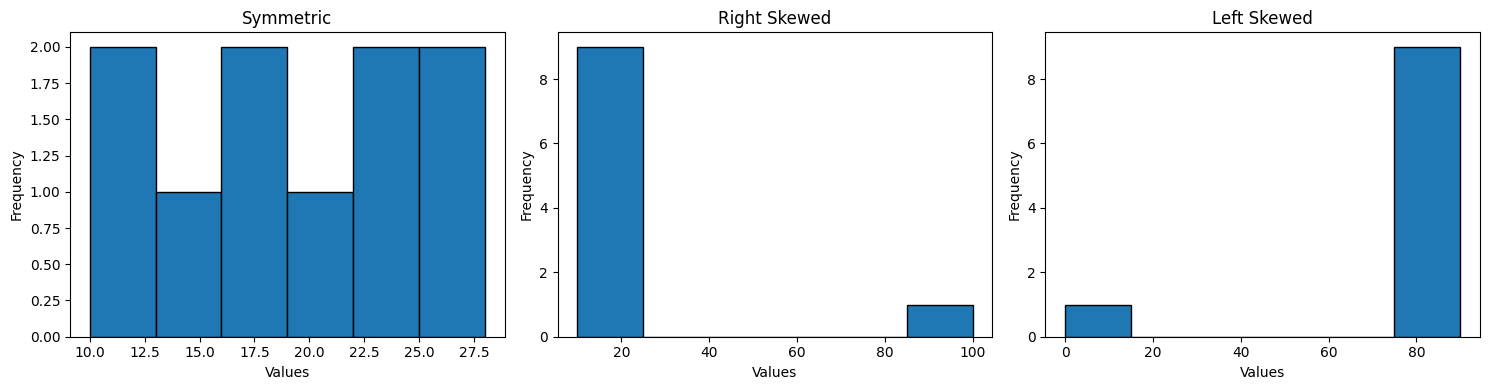

In [4]:
# Visualize all three distributions

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, df.columns):
    ax.hist(df[column], bins=6, edgecolor="black")
    ax.set_title(column.replace("_", " "))
    ax.set_xlabel("Values")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## 6. Skewness

Skewness measures the asymmetry of a data distribution.

It helps identify whether data values are concentrated more on one side.

There are three main types:

### A. Zero or Approximately Zero Skewness

- Distribution is approximately symmetric.
- Mean and median are generally close.

### B. Positive Skewness

- Distribution has a longer right tail.
- Mean is generally greater than median.

### C. Negative Skewness

- Distribution has a longer left tail.
- Mean is generally less than median.

**Important:** Skewness measures the direction and degree of asymmetry.

In [5]:
# Calculate skewness for each dataset

skewness_values = df.apply(
    lambda column: skew(column, bias=False)
)

skewness_values

,0
Symmetric,0.000000
Right_Skewed,3.092247
Left_Skewed,-3.092247


### Skewness Interpretation

- Skewness near zero indicates approximate symmetry.
- Positive skewness indicates a longer right tail.
- Negative skewness indicates a longer left tail.

The magnitude indicates the degree of asymmetry.

There are no universal cutoffs that classify every dataset as slightly or highly skewed. Interpretation also depends on the data and business context.

## 7. Mean and Median Comparison

Mean and median can help us understand the direction of skewness.

General patterns:

- Symmetric distribution: Mean ≈ Median
- Right-skewed distribution: Mean > Median
- Left-skewed distribution: Mean < Median

In [6]:
# Compare mean and median

central_tendency = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median()
})

central_tendency

,Mean,Median
Symmetric,19.0,19.0
Right_Skewed,23.5,15.5
Left_Skewed,76.5,84.5


### Business Interpretation

Consider customer purchase amounts:

- A few customers making very large purchases can create a right-skewed distribution.
- A few unusually small values can create a left-skewed distribution.
- A roughly symmetric distribution has values balanced around its center.

For skewed data, median can sometimes represent a typical observation better than mean.

## 8. Kurtosis

Kurtosis measures the heaviness of the tails of a distribution relative to a normal distribution.

It helps us understand the tendency of a distribution to produce extreme values.

We commonly interpret excess kurtosis:

### A. Mesokurtic

- Excess kurtosis is approximately zero.
- Has tail behavior similar to a normal distribution.

### B. Leptokurtic

- Positive excess kurtosis.
- Has heavier tails than a normal distribution.
- Extreme observations may be more likely.

### C. Platykurtic

- Negative excess kurtosis.
- Has lighter tails than a normal distribution.

**Important:** Kurtosis is not simply a measure of how peaked a graph looks. Tail heaviness is an important part of its interpretation.

In [7]:
# Calculate excess kurtosis for each dataset

kurtosis_values = df.apply(
    lambda column: kurtosis(
        column,
        fisher=True,
        bias=False
    )
)

kurtosis_values

,0
Symmetric,-1.200000
Right_Skewed,9.676476
Left_Skewed,9.676476


### Kurtosis Interpretation

- Positive excess kurtosis: Heavier tails relative to a normal distribution.
- Zero excess kurtosis: Similar tail behavior to a normal distribution.
- Negative excess kurtosis: Lighter tails relative to a normal distribution.

We are using Fisher's definition of kurtosis, where the normal distribution has an excess kurtosis of zero.

## 9. Compare Skewness and Kurtosis

Skewness and kurtosis describe different characteristics of a distribution.

| Measure | What It Measures |
|---|---|
| Skewness | Asymmetry and direction of a distribution |
| Kurtosis | Tail heaviness relative to a normal distribution |

### Key Difference

- Skewness tells us whether a distribution has a longer left or right tail.
- Kurtosis tells us about the heaviness of the distribution's tails.

A dataset can have zero skewness and still have positive or negative excess kurtosis.

In [8]:
# Create a combined distribution summary

distribution_summary = pd.DataFrame({
    "Mean": df.mean(),
    "Median": df.median(),

    "Skewness": df.apply(
        lambda column: skew(column, bias=False)
    ),

    "Excess_Kurtosis": df.apply(
        lambda column: kurtosis(
            column,
            fisher=True,
            bias=False
        )
    )
})

distribution_summary

,Mean,Median,Skewness,Excess_Kurtosis
Symmetric,19.0,19.0,0.000000,-1.200000
Right_Skewed,23.5,15.5,3.092247,9.676476
Left_Skewed,76.5,84.5,-3.092247,9.676476


## 10. Business Applications

### E-commerce and Retail

- Analyze customer purchase amounts.
- Identify high-value purchases.
- Understand customer spending patterns.

### Banking and Finance

- Analyze transaction amounts.
- Understand the distribution of financial returns.
- Investigate unusually large or small observations.

### Human Resources

- Analyze employee salary distributions.
- Understand salary differences across employees.

### Operations

- Analyze delivery times.
- Identify unusually delayed orders.
- Understand operational variability.

## 11. Important Statistical Observations

1. A symmetric distribution has approximately balanced tails.
2. Positive skewness indicates a longer right tail.
3. Negative skewness indicates a longer left tail.
4. Mean is generally pulled toward the longer tail.
5. Median is less affected by extreme observations.
6. Kurtosis helps describe tail heaviness.
7. Skewness and kurtosis provide different information about a distribution.

**Business Insight:**

Understanding distribution shape helps analysts select appropriate statistical measures and interpret business data more accurately.

## 12. Interview Questions

### Q1. What is skewness?

Skewness measures the asymmetry of a data distribution.

### Q2. What is positive skewness?

Positive skewness indicates a longer right tail, and the mean is generally greater than the median.

### Q3. What is negative skewness?

Negative skewness indicates a longer left tail, and the mean is generally less than the median.

### Q4. What is a symmetric distribution?

A symmetric distribution has approximately balanced left and right sides around its center.

### Q5. What is kurtosis?

Kurtosis measures the heaviness of distribution tails relative to a normal distribution.

### Q6. What is the difference between skewness and kurtosis?

Skewness measures asymmetry, whereas kurtosis describes tail heaviness.

### Q7. What does positive excess kurtosis indicate?

It indicates heavier tails relative to a normal distribution.

### Q8. Why is median useful for skewed data?

Median is less affected by extreme values and can better represent the center of a skewed dataset.

## 13. Practice Tasks

1. Create a dataset containing purchase amounts of 30 customers.
2. Calculate its mean and median.
3. Calculate skewness.
4. Calculate excess kurtosis.
5. Visualize the distribution using a histogram.
6. Identify whether the distribution is symmetric, positively skewed or negatively skewed.
7. Explain the business meaning of your findings.

## Conclusion

In this notebook, we learned how to understand data distribution using skewness and kurtosis.

We explored symmetric, positively skewed and negatively skewed distributions and calculated their statistical measures using Python.

These concepts are useful for exploratory data analysis, understanding business patterns and selecting appropriate statistical measures.

**Next Topic:** Basic Probability and Probability Rules.